# ITCS 6169/8169 — Computer Vision
## Vision Transformer (ViT) Experimental Template

A new template following the original notebook's organization: imports, project paths, reproducibility, preprocessing, seeded train/validation split, visualization, model, training utilities, experiment tracking, and final evaluation.

**Assignment warning:** The original Assignment 1 instructions require a ViT as the primary classifier and prohibit ViTs for the main submission. This notebook is for separate ViT experimentation/learning unless your instructor approves a change.


In [1]:
# Core imports
from pathlib import Path
import random, time, copy, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms
from IPython.display import display

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

PyTorch: 2.14.0+cu130
CUDA available: True


In [2]:
# Optional Google Drive mount for Colab
try:
    from google.colab import drive
    drive.mount('/content/gdrive')
except ImportError:
    print("Not running in Google Colab.")

Not running in Google Colab.


## 1. Set your working directory

Expected dataset structure:

```text
data/
  train/
    class_1/
    class_2/
  test/
    class_1/
    class_2/
```

In [3]:
# Change this path to your project directory.
# PROJECT_ROOT = Path('/content/gdrive/MyDrive/ITCS_6169_8169/assignment1')
PROJECT_ROOT = Path('.')
DATA_ROOT = PROJECT_ROOT / 'data'
TRAIN_ROOT = DATA_ROOT / 'train'
TEST_ROOT = DATA_ROOT / 'test'

print("Project root:", PROJECT_ROOT.resolve())
print("Training data:", TRAIN_ROOT)
print("Testing data:", TEST_ROOT)
assert TRAIN_ROOT.exists(), "Training directory not found."
assert TEST_ROOT.exists(), "Testing directory not found." 

Project root: /home/ward/MainDir/ComputerVision/Transformer
Training data: data/train
Testing data: data/test


## 2. Reproducibility and device

In [4]:
SEED = 0

def set_random_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_random_seed(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Using device:", device)

Using device: cuda


## 3. Loading and preprocessing the data

ViTs divide images into fixed-size patches, so image dimensions must be divisible by the patch size. This template keeps grayscale inputs to match the original notebook. For RGB, remove the grayscale transform and set `IN_CHANNELS = 3`.

In [117]:

# Data processing Values, such as image and patch size
IMG_SIZE = 120
PATCH_SIZE = 6
IN_CHANNELS = 1
BATCH_SIZE = 64
VAL_FRACTION = 0.20
NUM_WORKERS = 5

assert IMG_SIZE % PATCH_SIZE == 0

#############################################################################
# Data augmentation and Transforms

baseline_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=IN_CHANNELS),
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5], std=[0.5]),
])

# Adjust augmentation as part of your experiments.
train_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=IN_CHANNELS),
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.8, 1.0), ratio=(0.75, 1.333)),
    transforms.RandomHorizontalFlip(p=0.5),
     transforms.ColorJitter(brightness=0.1,contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5], std=[0.5]),
])


hard_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ColorJitter(
        brightness=0.3,
        contrast=0.6
    ),
    transforms.RandomResizedCrop(
        size=(IMG_SIZE, IMG_SIZE),
        scale=(.8, 1.0)
    ),
    transforms.RandomVerticalFlip(.5),
    transforms.RandomHorizontalFlip(p=.5),
    transforms.ToTensor(),
    transforms.RandomErasing(
        p=0.7,
        scale=(0.1, 0.30),
        ratio=(1, 1)
    ),
     transforms.RandomSolarize(.9, .4),
     # transforms.ColorJitter(
    #     brightness=0.5,
    #     contrast=0.5,
    # ),

    transforms.Normalize(mean=[0.5], std=[0.5]),

])
###############################################################################################
# Initialize data set configurations

full_train_dataset = datasets.ImageFolder(TRAIN_ROOT, transform=baseline_transform)
test_dataset = datasets.ImageFolder(TEST_ROOT, transform=baseline_transform)
class_names = full_train_dataset.classes
num_classes = len(class_names)


###############################################################################################
# Same split procedure as the original notebook:
# create seeded indices, then apply them to separate transformed datasets.
val_size = int(round(len(full_train_dataset) * VAL_FRACTION))
train_size = len(full_train_dataset) - val_size
generator = torch.Generator().manual_seed(SEED)

train_subset, val_subset = random_split(
    full_train_dataset, [train_size, val_size], generator=generator
)

train_full = datasets.ImageFolder(TRAIN_ROOT, transform=train_transform)
val_full = datasets.ImageFolder(TRAIN_ROOT, transform=baseline_transform)

train_dataset = torch.utils.data.Subset(train_full, train_subset.indices)
val_dataset = torch.utils.data.Subset(val_full, val_subset.indices)

assert test_dataset.class_to_idx == full_train_dataset.class_to_idx, (
    "Train and test class mappings do not match."
)

################################################################################################
train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available()
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available()
)
test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available()
)

################################################################################
# Mae traing set

# Every training-folder image, augmented
mae_train_dataset = datasets.ImageFolder(TRAIN_ROOT, transform=train_transform)

# Monitoring set: the same images with the plain transform (see note below)
mae_monitor_dataset = datasets.ImageFolder(TRAIN_ROOT, transform=baseline_transform)

mae_train_loader = DataLoader(
    mae_train_dataset, batch_size=BATCH_SIZE, shuffle=True, drop_last=True,
    num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available()
)
mae_monitor_loader = DataLoader(
    mae_monitor_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available()
)

print(f"MAE pretraining images: {len(mae_train_dataset)} "
      f"(was {len(train_dataset)} train + {len(val_dataset)} val)")

print("Classes:", class_names)
print(f"Train: {len(train_dataset)} | Validation: {len(val_dataset)} | Test: {len(test_dataset)}")

MAE pretraining images: 2400 (was 1920 train + 480 val)
Classes: ['Bedroom', 'Coast', 'Flower', 'Forest', 'Highway', 'Industrial', 'InsideCity', 'Kitchen', 'LivingRoom', 'Mountain', 'Office', 'OpenCountry', 'Store', 'Street', 'Suburb', 'TallBuilding']
Train: 1920 | Validation: 480 | Test: 400


### Dataset summary tables

The functions below display per-class counts and total image counts for each split.

In [118]:
def get_targets(dataset):
    """Get labels from ImageFolder or Subset(ImageFolder)."""
    if isinstance(dataset, torch.utils.data.Subset):
        targets = np.asarray(dataset.dataset.targets)
        return targets[np.asarray(dataset.indices)]
    if hasattr(dataset, "targets"):
        return np.asarray(dataset.targets)
    raise TypeError("Expected ImageFolder or Subset(ImageFolder).")


def display_dataset_tables(train_dataset, val_dataset, test_dataset, class_names):
    """Display per-class and per-split image counts as pandas tables."""
    split_datasets = {
        "Train": train_dataset,
        "Validation": val_dataset,
        "Test": test_dataset
    }
    rows = []
    for class_id, class_name in enumerate(class_names):
        row = {"Class": class_name}
        for split_name, dataset in split_datasets.items():
            row[split_name] = int(np.sum(get_targets(dataset) == class_id))
        rows.append(row)

    class_table = pd.DataFrame(rows)
    totals = {"Class": "TOTAL"}
    for split_name, dataset in split_datasets.items():
        totals[split_name] = len(dataset)
    class_table.loc[len(class_table)] = totals

    split_table = pd.DataFrame([
        {"Split": name, "Images": len(dataset)}
        for name, dataset in split_datasets.items()
    ])

    print("Images per class and split")
    display(class_table)
    print("Dataset split summary")
    display(split_table)
    return class_table, split_table


class_count_table, split_summary_table = display_dataset_tables(
    train_dataset, val_dataset, test_dataset, class_names
)

Images per class and split


,Class,Train,Validation,Test
0,Bedroom,111,39,25
1,Coast,117,33,25
2,Flower,119,31,25
3,Forest,121,29,25
4,Highway,122,28,25
5,Industrial,121,29,25
6,InsideCity,120,30,25
7,Kitchen,120,30,25
8,LivingRoom,124,26,25
9,Mountain,122,28,25


Dataset split summary


,Split,Images
0,Train,1920
1,Validation,480
2,Test,400


### Visualize training examples

The helper reverses normalization before displaying images.

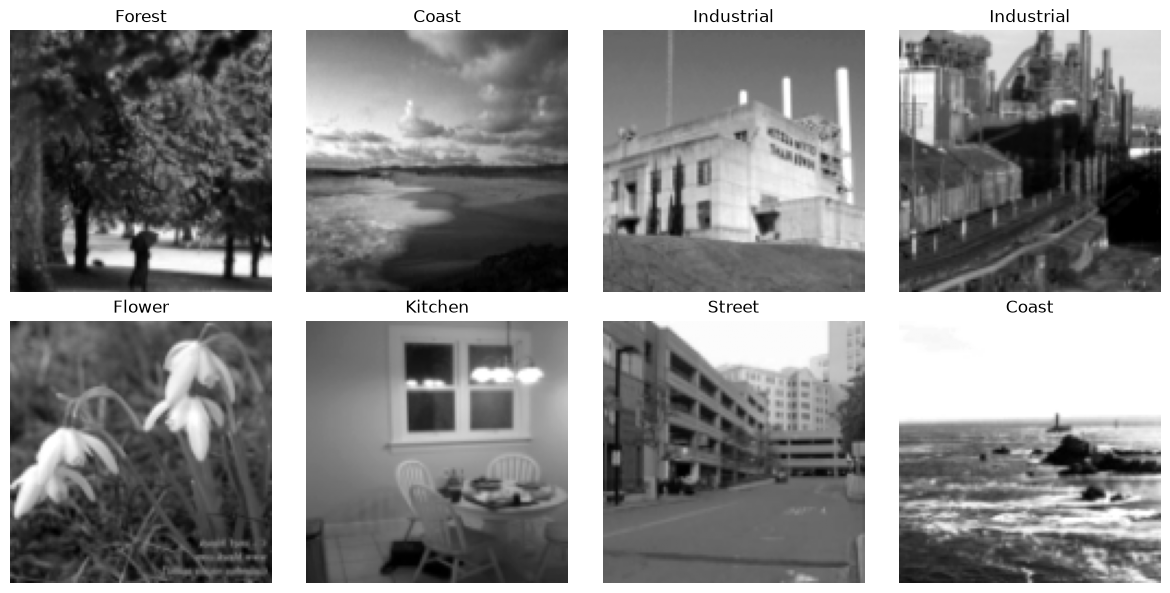

In [119]:
def show_image_batch(loader, class_names, max_images=8, mean=0.5, std=0.5):
    images, labels = next(iter(loader))
    count = min(max_images, len(images))
    cols = 4
    rows = math.ceil(count / cols)
    fig, axes = plt.subplots(rows, cols, figsize=(12, 3 * rows))
    axes = np.asarray(axes).reshape(-1)

    for ax in axes:
        ax.axis("off")

    for ax, image, label in zip(axes, images[:count], labels[:count]):
        image = (image * std + mean).clamp(0, 1)
        if image.shape[0] == 1:
            ax.imshow(image.squeeze(0), cmap="gray")
        else:
            ax.imshow(image.permute(1, 2, 0))
        ax.set_title(class_names[label.item()])
        ax.axis("off")

    plt.tight_layout()
    plt.show()

show_image_batch(train_loader, class_names)

## 4. Vision Transformer model

The model converts image patches into embeddings, adds a learnable class token and positional embeddings, processes the token sequence with Transformer encoder layers, and classifies using the class-token output.

In [120]:
class Masked_Auto_Encoder():

    def __init__(self):
        self.masked = None
        self.ids_keep = None
        self.ids_restore = None
        self.mask = None

    def token_masking(self, x, mask_ratio=0.75):

        B, N, D = x.shape

        num_keep = int(N * (1 - mask_ratio))

        noise = torch.rand(B, N, device=x.device)

        ids_shuffle = torch.argsort(noise, dim=1)

        # Inverse permutation for restoring original ordering
        ids_restore = torch.argsort(ids_shuffle, dim=1)

        ids_keep = ids_shuffle[:, :num_keep]

        x_masked = torch.gather(
            x,
            dim=1,
            index=ids_keep.unsqueeze(-1).expand(-1, -1, D)
        )

        # 0 = visible, 1 = masked
        mask = torch.ones(B, N, device=x.device)
        mask[:, :num_keep] = 0

        # Restore mask to original patch ordering
        mask = torch.gather(mask, dim=1, index=ids_restore)

        self.masked = x_masked
        self.ids_keep = ids_keep
        self.ids_restore = ids_restore
        self.mask = mask

        return x_masked, ids_restore, mask

class MAE_Decoder(nn.Module):

    def __init__(
        self,
        num_patches=64,
        encoder_dim=128,
        decoder_dim=128,
        patch_size=16,
        in_channels=1,
        num_heads=4,
        num_layers=4,
        mlp_dim=512,
        dropout=0.1
    ):

        super().__init__()

        # Step 1: Convert encoder output to decoder dimensions
        self.decoder_embed = nn.Linear(
            encoder_dim,
            decoder_dim
        )

        # Step 2: Create a learnable mask token
        self.mask_token = nn.Parameter(
            torch.zeros(1, 1, decoder_dim)
        )

        # Step 3: Positional embeddings for all original patches
        self.decoder_pos_embed = nn.Parameter(
            torch.zeros(1, num_patches, decoder_dim)
        )

        # Step 4: Create Transformer decoder layers
        decoder_layer = nn.TransformerEncoderLayer(
            d_model=decoder_dim,
            nhead=num_heads,
            dim_feedforward=mlp_dim,
            dropout=dropout,
            activation="gelu",
            batch_first=True
        )

        self.decoder = nn.TransformerEncoder(
            decoder_layer,
            num_layers=num_layers,
            norm=nn.LayerNorm(decoder_dim)
        )

        # Step 5: Predict the original pixels of each patch
        self.decoder_pred = nn.Linear(
            decoder_dim,
            patch_size * patch_size * in_channels
        )

        nn.init.trunc_normal_(self.mask_token, std=0.02)
        nn.init.trunc_normal_(self.decoder_pos_embed, std=0.02)




    def forward(self, x, ids_restore):
    
        # Step 1: Convert encoder output to decoder dimensions
        x = self.decoder_embed(x)
    
        # Step 2: Calculate how many mask tokens are needed
        num_masked = ids_restore.shape[1] - x.shape[1]
    
        # Step 3: Create the missing patch placeholders
        mask_tokens = self.mask_token.repeat(
            x.shape[0],
            num_masked,
            1
        )
    
        # Step 4: Append mask tokens to visible tokens
        x = torch.cat((x, mask_tokens), dim=1)
    
        # Step 5: Restore the original patch ordering
        x = torch.gather(
            x,
            dim=1,
            index=ids_restore.unsqueeze(-1).expand(
                -1, -1, x.shape[2]
            )
        )
    
        # Step 6: Add positional embeddings
        x = x + self.decoder_pos_embed
    
        # Step 7: Process all tokens through the decoder
        x = self.decoder(x)
    
        # Step 8: Predict pixel values for every patch
        x = self.decoder_pred(x)
    
        return x

class MAEClassifier(nn.Module):

    def __init__(self, mae_model, num_classes):
        super().__init__()

        # Reuse pretrained MAE encoder
        self.patch_embed = mae_model.patch_embed
        self.position_embedding = mae_model.position_embedding
        self.embedding_dropout = mae_model.embedding_dropout
        self.encoder = mae_model.encoder

        # Classification head
        embed_dim = self.position_embedding.shape[-1]

        self.classifier = nn.Linear(
            embed_dim,
            num_classes
        )

    def forward(self, images):

        # Patch embedding
        x = self.patch_embed(images)

        # Add positional embeddings
        x = x + self.position_embedding[:, 1:, :]

        x = self.embedding_dropout(x)

        # Process all patches (no masking)
        x = self.encoder(x)

        # Mean pool patch representations
        x = x.mean(dim=1)

        # Classification
        return self.classifier(x)

class MAE(nn.Module):
    def __init__(
        self,
        vit_model,
        num_patches=64,
        patch_size=16,
        in_channels=1,
        decoder_dim=128,
        decoder_heads=4,
        decoder_layers=4,
        decoder_mlp_dim=512,
        dropout=0.1,
        mask_ratio=0.75
    ):
        super().__init__()

        self.patch_embed = vit_model.patch_embed
        self.position_embedding = vit_model.position_embedding
        self.embedding_dropout = vit_model.embedding_dropout
        self.encoder = vit_model.transformer

        self.masking = Masked_Auto_Encoder()
        self.mask_ratio = mask_ratio

        # Get the actual encoder embedding dimension
        encoder_dim = vit_model.position_embedding.shape[-1]

        self.decoder = MAE_Decoder(
            num_patches=num_patches,
            encoder_dim=encoder_dim,
            decoder_dim=decoder_dim,
            patch_size=patch_size,
            in_channels=in_channels,
            num_heads=decoder_heads,
            num_layers=decoder_layers,
            mlp_dim=decoder_mlp_dim,
            dropout=dropout
        )

    def forward(self, images):
        x = self.patch_embed(images)

        x = x + self.position_embedding[:, 1:, :]
        x = self.embedding_dropout(x)

        x, ids_restore, mask = self.masking.token_masking(
            x,
            mask_ratio=self.mask_ratio
        )

        x = self.encoder(x)
        predictions = self.decoder(x, ids_restore)

        return predictions, mask

In [121]:
# This class acts as the Tokenizer creating vector representations of the patches generated per Convoloution
class PatchEmbedding(nn.Module):
    """Convert an image into a sequence of patch embeddings."""
    def __init__(self, img_size=128, patch_size=16, in_channels=1, embed_dim=192):
        super().__init__()
        assert img_size % patch_size == 0
        self.num_patches = (img_size // patch_size) ** 2
        self.projection = nn.Conv2d(
            in_channels, embed_dim,
            kernel_size=patch_size, stride=patch_size
        )

    def forward(self, x):
        # Defines behavior for when class is called like a function
        # Defines run order of Patch embedding
        
        x = self.projection(x)       # [B, embed_dim, patch_rows, patch_cols]
        x = x.flatten(2)             # [B, embed_dim, patch_count]
        return x.transpose(1, 2)     # [B, patch_count, embed_dim]

class VisionTransformer(nn.Module):

    def __init__(
        self, img_size=128, patch_size=16, in_channels=1,
        num_classes=16, embed_dim=128, num_heads=4,
        num_layers=6, mlp_dim=384, dropout=0.1
    ):
        # Defines and creates the resources for use
        super().__init__()

        # Stage 1: Patch embedding
        self.patch_embed = PatchEmbedding(
            img_size, patch_size, in_channels, embed_dim
        )

        num_patches = self.patch_embed.num_patches

        # Stage 2: Token preparation
        self.class_token = nn.Parameter(
            torch.zeros(1, 1, embed_dim)
        )

        self.position_embedding = nn.Parameter(
            torch.zeros(1, num_patches + 1, embed_dim)
        )

        # Mask Tokens
        self.masker = Masked_Auto_Encoder()

        self.embedding_dropout = nn.Dropout(dropout)

        # Stage 3: Transformer encoder
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=embed_dim,
            nhead=num_heads,
            dim_feedforward=mlp_dim,
            dropout=dropout,
            activation="gelu",
            batch_first=True,
            norm_first=False
        )

        self.transformer = nn.TransformerEncoder(
            encoder_layer,
            num_layers=num_layers,
            norm=nn.LayerNorm(embed_dim)
        )

        # Stage 4: Classification
        self.classifier = nn.Linear(embed_dim, num_classes)

        nn.init.trunc_normal_(self.class_token, std=0.02)
        nn.init.trunc_normal_(self.position_embedding, std=0.02)

        # Stage 5: MAE Decoder
        self.mae_decoder = MAE_Decoder(
            num_patches=num_patches,
            encoder_dim=embed_dim,
            decoder_dim=128,
            patch_size=patch_size,
            in_channels=in_channels,
            num_heads=4,
            num_layers=4,
            mlp_dim=512,
            dropout=dropout
        )
        
        # Create the masking component
       

    def prepare_tokens(self, x):
        # Prepares and patches the tokens

        # get an object reference to the PatchEmbedding Class
        x = self.patch_embed(x)

        class_token = self.class_token.expand(
            x.shape[0], -1, -1
        )

        x = torch.cat((class_token, x), dim=1)

        x = x + self.position_embedding

        return self.embedding_dropout(x)

    def forward(self, x):
        # Defines behavior for when class is called like a function
        # Defines run order of the Vision Transformer Model

        # Stage 1: Convert image into patch embeddings
        x = self.patch_embed(x)
    
        # Stage 2: Add positional embeddings
        # Skip position 0 because it belongs to the class token
        x = x + self.position_embedding[:, 1:, :]
        
        # Stage 3: Encoder processes visible patches
        x = self.transformer(x)
        
        return x, mask


EMBED_DIM = 128
NUM_LAYERS = 6
NUM_HEADS = 8
MLP_DIM = 512

DROPOUT = 0
model = VisionTransformer(
    img_size=IMG_SIZE, patch_size=PATCH_SIZE,
    in_channels=IN_CHANNELS, num_classes=num_classes,
    embed_dim=EMBED_DIM, num_heads=NUM_HEADS,
    num_layers=NUM_LAYERS, mlp_dim=MLP_DIM, dropout=DROPOUT
).to(device)

print(model)
print("Trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))

VisionTransformer(
  (patch_embed): PatchEmbedding(
    (projection): Conv2d(1, 128, kernel_size=(6, 6), stride=(6, 6))
  )
  (embedding_dropout): Dropout(p=0, inplace=False)
  (transformer): TransformerEncoder(
    (layers): ModuleList(
      (0-5): 6 x TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=128, out_features=128, bias=True)
        )
        (linear1): Linear(in_features=128, out_features=512, bias=True)
        (dropout): Dropout(p=0, inplace=False)
        (linear2): Linear(in_features=512, out_features=128, bias=True)
        (norm1): LayerNorm((128,), eps=1e-05, elementwise_affine=True, bias=True)
        (norm2): LayerNorm((128,), eps=1e-05, elementwise_affine=True, bias=True)
        (dropout1): Dropout(p=0, inplace=False)
        (dropout2): Dropout(p=0, inplace=False)
      )
    )
    (norm): LayerNorm((128,), eps=1e-05, elementwise_affine=True, bias=True)
  )
  (classifier): Linear(

## 5. Training and evaluation utilities

The training loop tracks loss and accuracy on both training and validation data and restores the checkpoint with the best validation accuracy.

In [105]:
def mae_loss(images, predictions, mask):

    targets = patchify(images, PATCH_SIZE)

    # Calculate squared error
    loss = (predictions - targets) ** 2

    # Average pixel error within each patch
    loss = loss.mean(dim=-1)

    # Only calculate loss on masked patches
    loss = (loss * mask).sum() / mask.sum()

    return loss

def patchify(images, patch_size):

    B, C, H, W = images.shape

    h = H // patch_size
    w = W // patch_size

    x = images.reshape(
        B, C, h, patch_size, w, patch_size
    )

    x = x.permute(0, 2, 4, 3, 5, 1)

    x = x.reshape(
        B, h * w, patch_size * patch_size * C
    )

    return x

def train_mae(
    model,
    train_loader,
    val_loader,
    optimizer,
    scheduler=None,
    epochs=50,
    device="cuda"
):
    history = {
        "train_loss": [],
        "val_loss": [],
        "train_reconstruction_loss": [],
        "val_reconstruction_loss": [],
        "learning_rate": []
    }

    for epoch in range(epochs):

        # -------------------------
        # Training
        # -------------------------
        model.train()

        running_train_loss = 0.0
        running_train_reconstruction = 0.0

        for images, _ in train_loader:
            images = images.to(device, non_blocking=True)

            optimizer.zero_grad(set_to_none=True)

            predictions, mask = model(images)

            reconstruction_loss = mae_loss(images, predictions, mask)
            loss = reconstruction_loss

            loss.backward()
            optimizer.step()

            batch_size = images.size(0)

            running_train_loss += loss.item() * batch_size
            running_train_reconstruction += reconstruction_loss.item() * batch_size

        train_loss = running_train_loss / len(train_loader.dataset)
        train_reconstruction = (
            running_train_reconstruction / len(train_loader.dataset)
        )

        # -------------------------
        # Validation
        # -------------------------
        model.eval()

        running_val_loss = 0.0
        running_val_reconstruction = 0.0

        with torch.no_grad():
            for images, _ in val_loader:
                images = images.to(device, non_blocking=True)

                predictions, mask = model(images)

                reconstruction_loss = mae_loss(images, predictions, mask)
                loss = reconstruction_loss

                batch_size = images.size(0)

                running_val_loss += loss.item() * batch_size
                running_val_reconstruction += reconstruction_loss.item() * batch_size

        val_loss = running_val_loss / len(val_loader.dataset)
        val_reconstruction = (
            running_val_reconstruction / len(val_loader.dataset)
        )

        # -------------------------
        # Learning rate
        # -------------------------
        current_lr = optimizer.param_groups[0]["lr"]

        if scheduler is not None:
            scheduler.step()

        # -------------------------
        # Save history
        # -------------------------
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)

        history["train_reconstruction_loss"].append(train_reconstruction)
        history["val_reconstruction_loss"].append(val_reconstruction)

        history["learning_rate"].append(current_lr)

        # -------------------------
        # Print results
        # -------------------------
        print(
            f"Epoch [{epoch + 1:02d}/{epochs}] | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Train Recon: {train_reconstruction:.4f} | "
            f"Val Recon: {val_reconstruction:.4f} | "
            f"LR: {current_lr:.6f}"
        )

    return model, history

In [106]:
def train_classifier(
    model,
    train_loader,
    val_loader,
    optimizer,
    scheduler=None,
    epochs=30,
    device="cuda"
):

    criterion = nn.CrossEntropyLoss()

    history = {
        "train_loss": [],
        "val_loss": [],
        "train_acc": [],
        "val_acc": [],
        "learning_rate": []
    }

    for epoch in range(epochs):

        # Training
        model.train()

        train_loss = 0.0
        train_correct = 0
        train_total = 0

        for images, labels in train_loader:

            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            optimizer.zero_grad(set_to_none=True)

            outputs = model(images)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            train_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)

            train_correct += (predictions == labels).sum().item()
            train_total += labels.size(0)

        train_loss /= train_total
        train_accuracy = 100 * train_correct / train_total

        # Validation
        model.eval()

        val_loss = 0.0
        val_correct = 0
        val_total = 0

        with torch.no_grad():

            for images, labels in val_loader:

                images = images.to(device, non_blocking=True)
                labels = labels.to(device, non_blocking=True)

                outputs = model(images)
                loss = criterion(outputs, labels)

                val_loss += loss.item() * images.size(0)

                predictions = outputs.argmax(dim=1)

                val_correct += (predictions == labels).sum().item()
                val_total += labels.size(0)

        val_loss /= val_total
        val_accuracy = 100 * val_correct / val_total

        current_lr = optimizer.param_groups[0]["lr"]

        if scheduler is not None:
            scheduler.step()

        # Save history
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_accuracy)
        history["val_acc"].append(val_accuracy)
        history["learning_rate"].append(current_lr)

        print(
            f"Epoch [{epoch + 1:02d}/{epochs}] | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Train Acc: {train_accuracy:.2f}% | "
            f"Val Acc: {val_accuracy:.2f}% | "
            f"LR: {current_lr:.6f}"
        )

    return model, history

In [107]:
@torch.inference_mode()
def evaluate(model, loader, device):
    model.eval()
    criterion = nn.CrossEntropyLoss()
    total_loss, total_correct, total_seen = 0.0, 0, 0

    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        logits = model(images)
        loss = criterion(logits, labels)
        total_loss += loss.item() * images.size(0)
        total_correct += (logits.argmax(dim=1) == labels).sum().item()
        total_seen += labels.size(0)

    return total_loss / total_seen, total_correct / total_seen


def train_model(model, train_loader, val_loader, optimizer,
                scheduler=None, epochs=20, device=device):
    criterion = nn.CrossEntropyLoss()
    model = model.to(device)
    best_state = copy.deepcopy(model.state_dict())
    best_val_acc = -1.0
    history = {
        "train_loss": [], "train_acc": [],
        "val_loss": [], "val_acc": [], "lr": []
    }
    start = time.time()

    for epoch in range(1, epochs + 1):
        model.train()
        total_loss, total_correct, total_seen = 0.0, 0, 0

        for images, labels in train_loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            logits = model(images)
            loss = criterion(logits, labels)
            loss.backward()
            optimizer.step()

            total_loss += loss.item() * images.size(0)
            total_correct += (logits.argmax(dim=1) == labels).sum().item()
            total_seen += labels.size(0)

        train_loss = total_loss / total_seen
        train_acc = total_correct / total_seen
        val_loss, val_acc = evaluate(model, val_loader, device)
        current_lr = optimizer.param_groups[0]["lr"]

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)
        history["lr"].append(current_lr)

        if scheduler is not None:
            if isinstance(scheduler, optim.lr_scheduler.ReduceLROnPlateau):
                scheduler.step(val_loss)
            else:
                scheduler.step()

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_state = copy.deepcopy(model.state_dict())

        print(
            f"Epoch {epoch:02d}/{epochs} | train loss {train_loss:.4f} | "
            f"train acc {train_acc:.4f} | val loss {val_loss:.4f} | "
            f"val acc {val_acc:.4f} | lr {current_lr:.6g} | "
            f"{time.time() - start:.1f}s"
        )

    model.load_state_dict(best_state)
    print(f"Best validation accuracy: {best_val_acc:.4f}")
    return model, history


def display_history_table(history):
    """Display per-epoch training metrics as a pandas table."""
    table = pd.DataFrame(history)
    table.insert(0, "epoch", np.arange(1, len(table) + 1))
    display(table)
    return table


def plot_training_history(history):
    epochs = range(1, len(history["train_loss"]) + 1)
    plt.figure(figsize=(7, 4))
    plt.plot(epochs, history["train_loss"], label="Train loss")
    plt.plot(epochs, history["val_loss"], label="Validation loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.grid(alpha=0.25)
    plt.show()

    plt.figure(figsize=(7, 4))
    plt.plot(epochs, history["train_acc"], label="Train accuracy")
    plt.plot(epochs, history["val_acc"], label="Validation accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()
    plt.grid(alpha=0.25)
    plt.show()

### 5.1 Configure and run an experiment

Recreate the model for a fresh run so it starts with newly initialized weights.

In [111]:
gc.collect()
torch.cuda.empty_cache()

print(
    f"Available GPU memory: "
    f"{torch.cuda.mem_get_info()[0] / 1024**3:.2f} GB"
)

Available GPU memory: 4.90 GB


In [ ]:
set_random_seed(SEED)
import gc
import torch

EMBED_DIM = 192
NUM_LAYERS = 4
NUM_HEADS = 4
MLP_DIM = 768

# -------------------------
# Create ViT Encoder
# -------------------------
vit_encoder = VisionTransformer(
    img_size=IMG_SIZE,
    patch_size=PATCH_SIZE,
    in_channels=IN_CHANNELS,
    num_classes=num_classes,
    embed_dim=EMBED_DIM,
    num_heads=NUM_HEADS,
    num_layers=NUM_LAYERS,
    mlp_dim=MLP_DIM,
    dropout=DROPOUT
)

# -------------------------
# Create MAE
# -------------------------
NUM_PATCHES = (IMG_SIZE // PATCH_SIZE) ** 2
DECODER_EMBED_DIM = 128
DECODER_NUM_LAYERS = 2
DECODER_NUM_HEADS = 4
DECODER_MLP_DIM = 512


mae_model = MAE(
    vit_model=vit_encoder,
    num_patches=NUM_PATCHES,
    patch_size=PATCH_SIZE,
    in_channels=IN_CHANNELS,
    decoder_dim=DECODER_EMBED_DIM,
    decoder_heads=DECODER_NUM_HEADS,
    decoder_layers=DECODER_NUM_LAYERS,
    decoder_mlp_dim=DECODER_MLP_DIM,
    dropout=DROPOUT,
    mask_ratio=0.25
).to(device)

# -------------------------
# Training Configuration
# -------------------------
LEARNING_RATE = 3e-4
WEIGHT_DECAY = 1e-4
EPOCHS = 60

optimizer = optim.AdamW(
    mae_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

scheduler = optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=EPOCHS
)


# -------------------------
# MAE Pretraining
# -------------------------
mae_model, mae_history = train_mae(
    mae_model,
    mae_train_loader,
    mae_monitor_loader,
    optimizer,
    scheduler=scheduler,
    epochs=EPOCHS,
    device=device
)
torch.save(
    mae_model.state_dict(),
    "pretrained2_mae.pth"
)


# plot_training_history(mae_history)

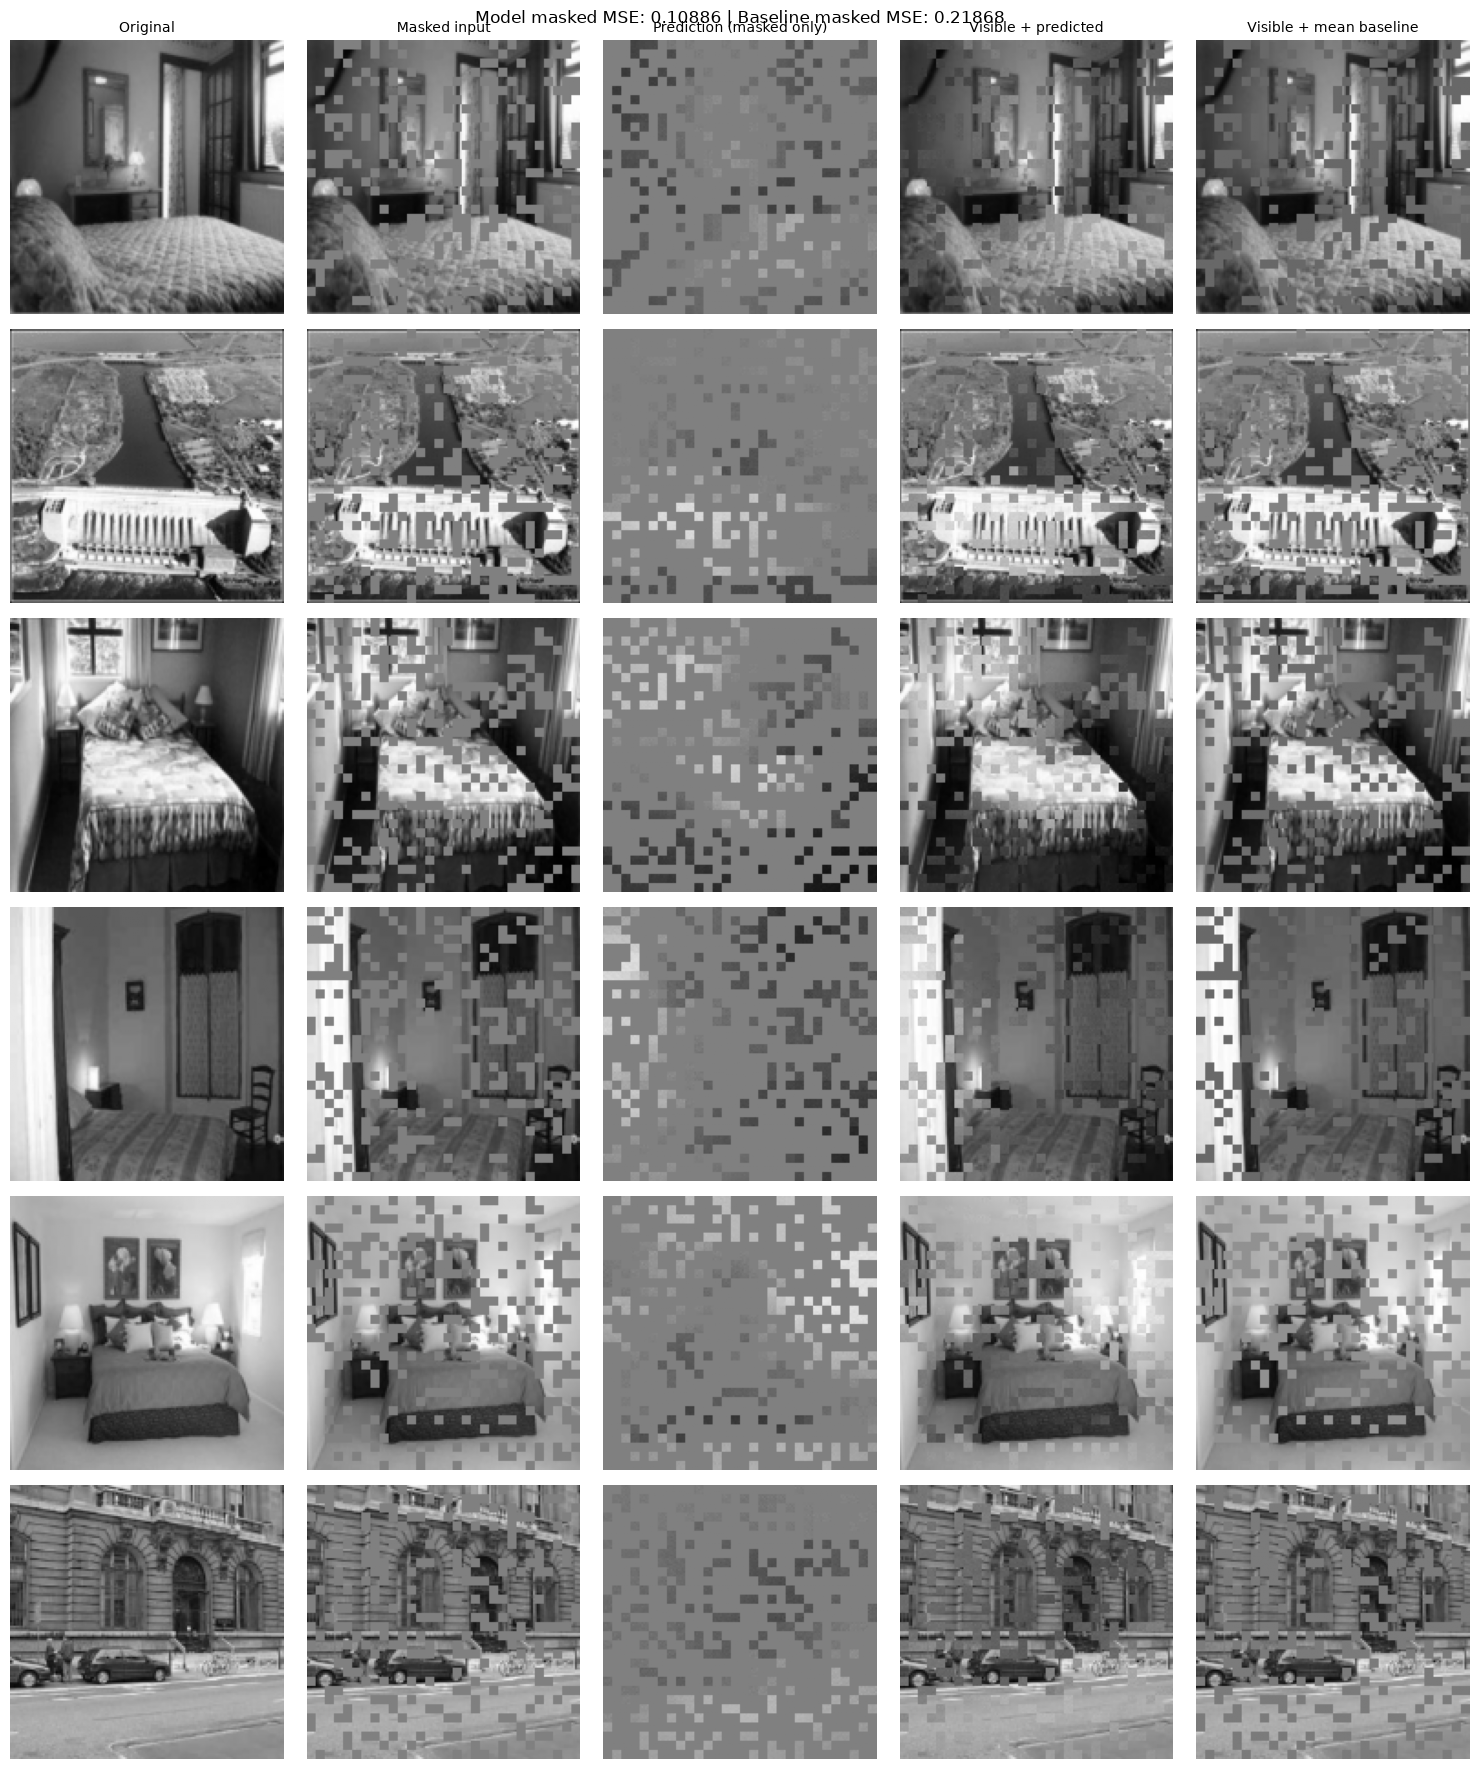


--- MAE Reconstruction Diagnostics ---
Original normalized range: [-1.0000, 1.0000]
Prediction range: [-2.2309, 2.0740]
Model masked-patch MSE: 0.108858
Visible-mean baseline MSE: 0.218678
Model improvement over baseline: 50.22%


In [113]:

def unpatchify(patches, patch_size, channels=1):
    """Exact inverse of patchify(): [B, N, p*p*C] -> [B, C, H, W]."""
    B, N, _ = patches.shape
    h = w = int(N ** 0.5)

    x = patches.reshape(B, h, w, patch_size, patch_size, channels)
    x = x.permute(0, 5, 1, 3, 2, 4)

    return x.reshape(B, channels, h * patch_size, w * patch_size)


@torch.no_grad()
def visualize_mae_reconstructions(
    mae_model, loader, n=6, norm_pix=False, seed=0,
    mean=0.5, std=0.5
):
    """
    Columns:
        Original | Masked input | Prediction (masked only)
        Visible + predicted | Visible + mean baseline

    Assumes images were normalized using mean/std.
    Set norm_pix=True if using per-patch target normalization.
    """

    mae_model.eval()

    images, _ = next(iter(loader))
    images = images[:n].to(device)

    torch.manual_seed(seed)

    preds, mask = mae_model(images)

    target = patchify(images, PATCH_SIZE)

    B, N, D = target.shape

    # Undo per-patch normalization if used during training
    if norm_pix:
        patch_var, patch_mean_original = torch.var_mean(
            target, dim=-1, keepdim=True, correction=1
        )

        preds = (
            preds * (patch_var + 1e-6).sqrt()
            + patch_mean_original
        )

    m3 = mask.unsqueeze(-1)

    # Visible and masked patches
    visible = 1 - m3

    masked_input = target * visible

    # Reconstruction
    recon_only = preds * m3
    pasted = target * visible + preds * m3

    # Visible-patch mean baseline
    visible_count = visible.sum(dim=1, keepdim=True)

    visible_mean = (
        (target * visible).sum(dim=(1, 2), keepdim=True)
        / (visible_count * D).clamp_min(1)
    )

    visible_mean = visible_mean.expand_as(target)

    baseline = target * visible + visible_mean * m3

    # Masked-patch MSE
    denominator = mask.sum(dim=1).clamp_min(1)

    mse_model = (
        ((preds - target) ** 2).mean(dim=-1) * mask
    ).sum(dim=1) / denominator

    mse_base = (
        ((visible_mean - target) ** 2).mean(dim=-1) * mask
    ).sum(dim=1) / denominator

    # Convert patches back to images and undo dataset normalization
    def to_img(patches):
        x = unpatchify(
            patches,
            PATCH_SIZE,
            IN_CHANNELS
        )

        x = x * std + mean

        return x.clamp(0, 1).cpu()

    columns = [
        ("Original", to_img(target)),
        ("Masked input", to_img(masked_input)),
        ("Prediction (masked only)", to_img(recon_only)),
        ("Visible + predicted", to_img(pasted)),
        ("Visible + mean baseline", to_img(baseline)),
    ]

    fig, axes = plt.subplots(
        n, len(columns),
        figsize=(3 * len(columns), 3 * n),
        squeeze=False
    )

    for r in range(n):
        for c, (title, imgs) in enumerate(columns):

            img = imgs[r]
            ax = axes[r, c]

            if img.shape[0] == 1:
                ax.imshow(
                    img.squeeze(0),
                    cmap="gray",
                    vmin=0,
                    vmax=1
                )
            else:
                ax.imshow(img.permute(1, 2, 0))

            ax.axis("off")

            if r == 0:
                ax.set_title(title, fontsize=10)

    # Put MSE information in the figure title instead
    fig.suptitle(
        f"Model masked MSE: {mse_model.mean():.5f} | "
        f"Baseline masked MSE: {mse_base.mean():.5f}",
        fontsize=12
    )

    plt.tight_layout()
    plt.show()

    # Additional diagnostics
    print("\n--- MAE Reconstruction Diagnostics ---")

    print(
        f"Original normalized range: "
        f"[{images.min().item():.4f}, "
        f"{images.max().item():.4f}]"
    )

    print(
        f"Prediction range: "
        f"[{preds.min().item():.4f}, "
        f"{preds.max().item():.4f}]"
    )

    print(
        f"Model masked-patch MSE: "
        f"{mse_model.mean().item():.6f}"
    )

    print(
        f"Visible-mean baseline MSE: "
        f"{mse_base.mean().item():.6f}"
    )

    print(
        f"Model improvement over baseline: "
        f"{(1 - mse_model.mean() / mse_base.mean().clamp_min(1e-8)).item() * 100:.2f}%"
    )


# Usage
visualize_mae_reconstructions(
    mae_model,
    val_loader,
    n=6,
    norm_pix=False
)


In [52]:
# set_random_seed(SEED)
# vit_rand = VisionTransformer(
#     img_size=IMG_SIZE, patch_size=PATCH_SIZE, in_channels=IN_CHANNELS,
#     num_classes=num_classes, embed_dim=EMBED_DIM, num_heads=NUM_HEADS,
#     num_layers=NUM_LAYERS, mlp_dim=MLP_DIM, dropout=DROPOUT)

# # untrained MAE wrapper, only used to hand its random encoder to MAEClassifier
# mae_rand = MAE(vit_model=vit_rand, num_patches=NUM_PATCHES, patch_size=PATCH_SIZE,
#                in_channels=IN_CHANNELS, decoder_dim=EMBED_DIM, decoder_heads=NUM_HEADS,
#                decoder_layers=2, decoder_mlp_dim=MLP_DIM, dropout=0.0, mask_ratio=0.75)

# classifier_rand = MAEClassifier(mae_rand, num_classes).to(device)

In [115]:
import math

EPOCHS      = 90
WARMUP      = 5          # epochs
ENCODER_LR  = 1e-4       # pretrained parts: small
HEAD_LR     = 1e-3       # new head: larger
WEIGHT_DECAY = 0.05

torch.cuda.empty_cache()

# Load saved weights
checkpoint = torch.load(
    "pretrained_mae.pth",
    map_location=device,
    weights_only=True
)

mae_model.load_state_dict(checkpoint)

# Freeze pretrained components
classifier = MAEClassifier(
    mae_model=mae_model,
    num_classes=16
).to(device)


# Make sure everything is trainable
for p in classifier.parameters():
    p.requires_grad = True

def split_decay(params):
    """Weight decay only on >=2-D weights; none on biases, norms, pos-embeddings."""
    decay, no_decay = [], []
    for p in params:
        (no_decay if p.ndim < 2 or p.shape == classifier.position_embedding.shape
         else decay).append(p)
    return decay, no_decay

enc_params = (list(classifier.patch_embed.parameters())
              + list(classifier.encoder.parameters())
              + [classifier.position_embedding])
enc_decay, enc_no_decay = split_decay(enc_params)
head_decay, head_no_decay = split_decay(list(classifier.classifier.parameters()))

optimizer = torch.optim.AdamW([
    {"params": enc_decay,     "lr": ENCODER_LR, "weight_decay": WEIGHT_DECAY},
    {"params": enc_no_decay,  "lr": ENCODER_LR, "weight_decay": 0.0},
    {"params": head_decay,    "lr": HEAD_LR,    "weight_decay": WEIGHT_DECAY},
    {"params": head_no_decay, "lr": HEAD_LR,    "weight_decay": 0.0},
], betas=(0.9, 0.999))

# Per-epoch warmup + cosine. The lambda scales each group's own base LR.
def lr_lambda(epoch):
    if epoch < WARMUP:
        return (epoch + 1) / WARMUP
    progress = (epoch - WARMUP) / max(1, EPOCHS - WARMUP)
    return 0.01 + 0.99 * 0.5 * (1 + math.cos(math.pi * progress))

scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)

classifier, classification_history = train_classifier(
    classifier, train_loader, val_loader, optimizer,
    scheduler=scheduler,       # <-- you weren't passing this before
    epochs=EPOCHS, device=device
)

Epoch [01/90] | Train Loss: 2.7824 | Val Loss: 2.7467 | Train Acc: 7.40% | Val Acc: 9.38% | LR: 0.000020
Epoch [02/90] | Train Loss: 2.7080 | Val Loss: 2.6419 | Train Acc: 13.28% | Val Acc: 18.33% | LR: 0.000040
Epoch [03/90] | Train Loss: 2.6270 | Val Loss: 2.5632 | Train Acc: 16.51% | Val Acc: 23.12% | LR: 0.000060
Epoch [04/90] | Train Loss: 2.5543 | Val Loss: 2.4527 | Train Acc: 18.33% | Val Acc: 26.46% | LR: 0.000080
Epoch [05/90] | Train Loss: 2.4404 | Val Loss: 2.3410 | Train Acc: 22.86% | Val Acc: 27.71% | LR: 0.000100
Epoch [06/90] | Train Loss: 2.2996 | Val Loss: 2.2541 | Train Acc: 26.98% | Val Acc: 30.42% | LR: 0.000100
Epoch [07/90] | Train Loss: 2.2042 | Val Loss: 2.2071 | Train Acc: 29.43% | Val Acc: 30.83% | LR: 0.000100
Epoch [08/90] | Train Loss: 2.1083 | Val Loss: 2.0980 | Train Acc: 32.14% | Val Acc: 32.92% | LR: 0.000100
Epoch [09/90] | Train Loss: 2.0014 | Val Loss: 2.0130 | Train Acc: 34.95% | Val Acc: 35.83% | LR: 0.000100
Epoch [10/90] | Train Loss: 1.9118 | Va

Encoder shared: True
Patch embedding shared: True
Position embedding shared: True


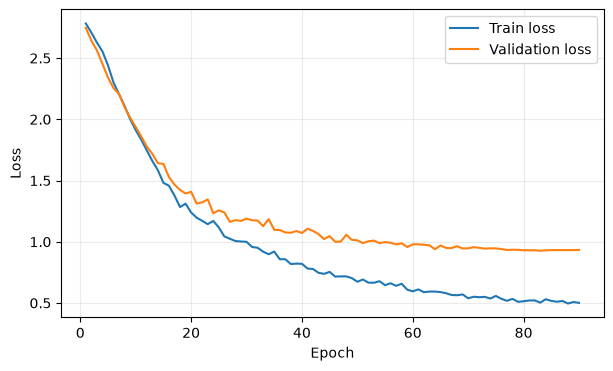

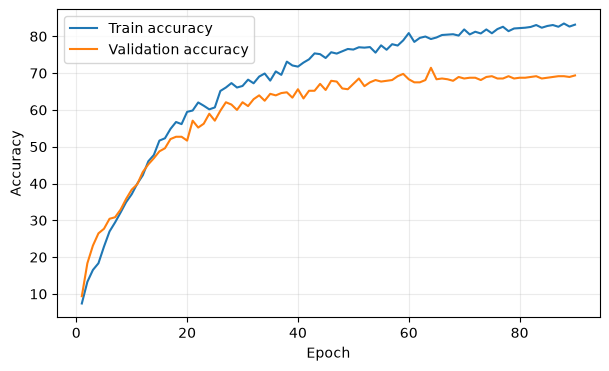

In [116]:
# After training:
classifier = MAEClassifier(
    mae_model=mae_model,
    num_classes=num_classes
).to(device)

print("Encoder shared:",
      classifier.encoder is mae_model.encoder)

print("Patch embedding shared:",
      classifier.patch_embed is mae_model.patch_embed)

print("Position embedding shared:",
      classifier.position_embedding is mae_model.position_embedding)
plot_training_history(classification_history)


## 6. Experiment notes and model improvements

Record architecture and training changes. Possible experiments include patch size, image resolution, embedding dimension, attention heads, encoder depth, MLP dimension, dropout, augmentation, optimizer, learning rate, and weight decay. Use validation results for model selection; do not repeatedly tune on the test set.

## 6. Your turn: beat the baseline

This simple model should only be treated as a sanity check. The objective is to substantially improve its performance.

Rather than asking an AI tool to "make the accuracy higher," I formulated hypotheses about possible limitations of the model and tested them experimentally. Examples of the questions I considered included whether the model was overfitting, whether color information mattered, whether stronger augmentation would help, whether a different ViT architecture would be more appropriate, whether pretrained ViT
features would transfer well, and whether optimization or regularization was limiting performance.

For each important experiment, I recorded what I changed, why I changed it, and what I learned from the results.

| Experiment | What changed? | Why did you try it? | Validation accuracy | What did you learn? |
|---|---|---|---:|---|
| Baseline | Starter TNet | Sanity check | .5125 | -- |
| Experiment 1 | I added MAE | I thought that MAE would initialize the weights to an more optimal starting position | 60  | I learned that MAE is great for preventing overfitting. My experiment shows evidence of undersfitting where the validation accuracy  is higher than the training. |
| | | | | |
| | | | | |

**Do not use the test set to choose among these experiments.**

## 7. Final test evaluation

Run this only after selecting the final model using validation results.

In [ ]:
test_loss, test_acc = evaluate(model, test_loader, device)
print(f"Final test loss: {test_loss:.4f}")
print(f"Final test accuracy: {test_acc:.4f}")

## 8. AI-assisted development checkpoint

If you use an AI coding assistant, document the tools used, representative ways AI assisted, at least one incorrect or ineffective suggestion, how you verified or corrected it, and one important decision you made yourself. Verify tensor shapes, assumptions, and code behavior before relying on generated code.

## 9. GitHub and project requirements

Keep your code and experiment history in GitHub. A useful repository may contain:

```text
README.md
AI_USAGE.md
notebooks/
    vision_transformer_template.ipynb
model code
training / evaluation code
requirements.txt
reproduction instructions
final checkpoint or a link to it
```

Record the final configuration, validation/model-selection strategy, test result, important experiments, and failure analysis. Be prepared to explain patch embedding, positional embeddings, self-attention, the Transformer encoder, and the classification head.